In [17]:
import os, random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

os.makedirs("models", exist_ok=True)
os.makedirs("assets", exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [18]:
!pip install -q datasets

In [19]:
from datasets import load_dataset
from sklearn.model_selection import train_test_split

ds = load_dataset("stanfordnlp/imdb")

X_trainval = np.array(ds["train"]["text"])
y_trainval = np.array(ds["train"]["label"])
X_test = np.array(ds["test"]["text"])
y_test = np.array(ds["test"]["label"])

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.2, stratify=y_trainval, random_state=SEED
)

print("Train:", len(X_train), "| Val:", len(X_val), "| Test:", len(X_test))
print("Balance train (0=neg, 1=pos):", np.bincount(y_train))
print("Ejemplo:", X_train[0][:200], "->", y_train[0])

Train: 20000 | Val: 5000 | Test: 25000
Balance train (0=neg, 1=pos): [10000 10000]
Ejemplo: I have always been a huge James Bond fanatic! I have seen almost all of the films except for Die Another Day, and The World Is Not Enough. The graphic's for Everything Or Nothing are breathtaking! The -> 1


In [20]:
MAX_TOKENS = 20000
SEQ_LEN = 200

vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_sequence_length=SEQ_LEN,
    standardize="lower_and_strip_punctuation",
)
vectorizer.adapt(X_train)

vocab = vectorizer.get_vocabulary()
print("Tamaño del vocabulario:", len(vocab))
print("Primeras 15 palabras:", vocab[:15])

ejemplo = vectorizer(np.array([X_train[0]]))
print("Reseña vectorizada (primeros 20 números):", ejemplo.numpy()[0][:20])

Tamaño del vocabulario: 20000
Primeras 15 palabras: ['', '[UNK]', np.str_('the'), np.str_('and'), np.str_('a'), np.str_('of'), np.str_('to'), np.str_('is'), np.str_('in'), np.str_('it'), np.str_('i'), np.str_('this'), np.str_('that'), np.str_('br'), np.str_('was')]
Reseña vectorizada (primeros 20 números): [  10   26  203   77    4  644  558 1548 7283   10   26  107  214   32
    5    2   97  542   16  855]


In [21]:
def build_base():
    inp = tf.keras.Input(shape=(1,), dtype=tf.string)
    x = vectorizer(inp)
    x = tf.keras.layers.Embedding(MAX_TOKENS, 64)(x)
    x = tf.keras.layers.GlobalAveragePooling1D()(x)
    x = tf.keras.layers.Dense(32, activation="relu")(x)
    out = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    m = tf.keras.Model(inp, out, name="base_embedding_dense")
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy", metrics=["accuracy"])
    return m

def build_mejorado():
    inp = tf.keras.Input(shape=(1,), dtype=tf.string)
    x = vectorizer(inp)
    x = tf.keras.layers.Embedding(MAX_TOKENS, 64, mask_zero=True)(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    x = tf.keras.layers.LSTM(64)(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    out = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    m = tf.keras.Model(inp, out, name="mejorado_embedding_lstm")
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy", metrics=["accuracy"])
    return m

base = build_base()
base.summary()

mejorado = build_mejorado()
mejorado.summary()

Model: "base_embedding_dense"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 1)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ text_vectorization_1            │ (None, 200)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_2 (Embedding)         │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,282,113 (4.89 MB)

 Trainable params: 1,282,113 (4.89 MB)

 Non-trainable params: 0 (0.00 B)

Model: "mejorado_embedding_lstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 200)       │          0 │ input_layer_3[0]… │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 200, 64)   │  1,280,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 200, 64)   │          0 │ embedding_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 200)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 64)        │     33,024 │ dropout_2[0][0],  │
│                     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 1)         │         65 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,313,089 (5.01 MB)

 Trainable params: 1,313,089 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
X_train = np.array(X_train.tolist(), dtype=object)
X_val   = np.array(X_val.tolist(),   dtype=object)
X_test  = np.array(X_test.tolist(),  dtype=object)

print(X_train.dtype, X_val.dtype, X_test.dtype)
print(type(X_train[0]), len(X_train), len(X_val), len(X_test))

object object object
<class 'str'> 20000 5000 25000


In [23]:
es = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=2, restore_best_weights=True
)

print("=== Entrenando BASE ===")
h_base = base.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10, batch_size=64, callbacks=[es]
)

print("\n=== Entrenando MEJORADO ===")
h_mej = mejorado.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10, batch_size=64, callbacks=[es]
)

=== Entrenando BASE ===
Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.7270 - loss: 0.5599 - val_accuracy: 0.8300 - val_loss: 0.3959
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8709 - loss: 0.3164 - val_accuracy: 0.8652 - val_loss: 0.3181
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9112 - loss: 0.2329 - val_accuracy: 0.8710 - val_loss: 0.3075
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9347 - loss: 0.1809 - val_accuracy: 0.8720 - val_loss: 0.3135
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9542 - loss: 0.1418 - val_accuracy: 0.8712 - val_loss: 0.3313

=== Entrenando MEJORADO ===
Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.7322 - loss: 0.5340 - val_accuracy: 0.8400 - val_loss: 0.3673
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.8808 - loss: 0.3037 - val_accuracy: 0.8604 - val_loss: 0.3455


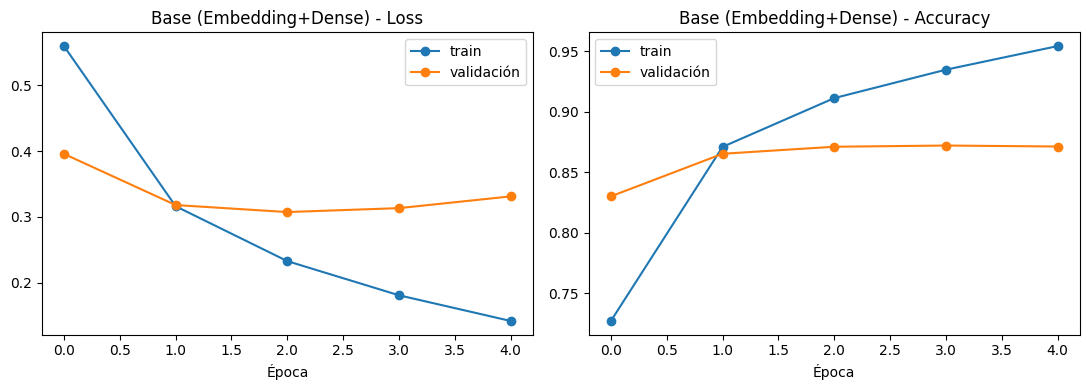

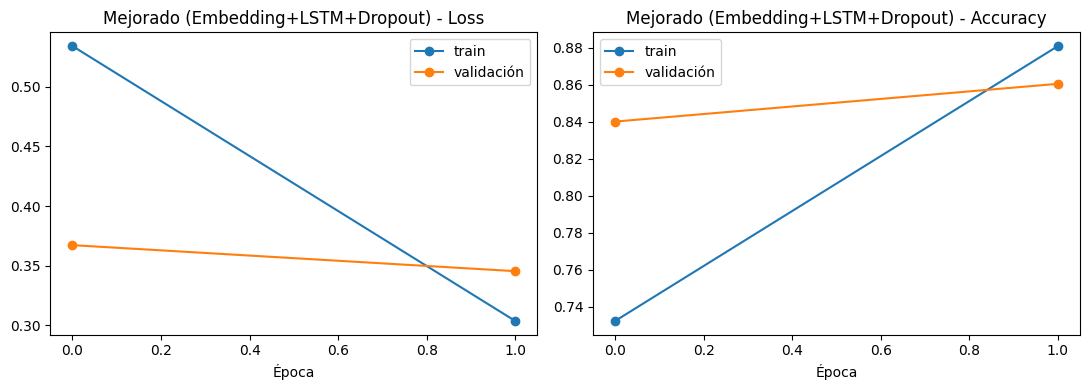

Épocas base: 5
Épocas mejorado: 2
Mejor val_loss base: 0.3075 en época 3
Mejor val_loss mejorado: 0.3455 en época 2


In [24]:
def plot_curves(h, nombre, fname):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h.history["loss"], marker="o", label="train")
    ax[0].plot(h.history["val_loss"], marker="o", label="validación")
    ax[0].set_title(f"{nombre} - Loss"); ax[0].set_xlabel("Época"); ax[0].legend()
    ax[1].plot(h.history["accuracy"], marker="o", label="train")
    ax[1].plot(h.history["val_accuracy"], marker="o", label="validación")
    ax[1].set_title(f"{nombre} - Accuracy"); ax[1].set_xlabel("Época"); ax[1].legend()
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()

plot_curves(h_base, "Base (Embedding+Dense)", "assets/curvas_base.png")
plot_curves(h_mej, "Mejorado (Embedding+LSTM+Dropout)", "assets/curvas_mejorado.png")

print("Épocas base:", len(h_base.history["loss"]))
print("Épocas mejorado:", len(h_mej.history["loss"]))
print("Mejor val_loss base:", round(min(h_base.history["val_loss"]), 4),
      "en época", int(np.argmin(h_base.history["val_loss"])) + 1)
print("Mejor val_loss mejorado:", round(min(h_mej.history["val_loss"]), 4),
      "en época", int(np.argmin(h_mej.history["val_loss"])) + 1)

In [25]:
res = []
for nombre, m, h in [("Base", base, h_base), ("Mejorado", mejorado, h_mej)]:
    tl, ta = m.evaluate(X_test, y_test, verbose=0)
    res.append({
        "modelo": nombre,
        "epocas": len(h.history["loss"]),
        "train_acc_final": h.history["accuracy"][-1],
        "val_acc_final": h.history["val_accuracy"][-1],
        "test_loss": tl,
        "test_acc": ta,
    })

df_res = pd.DataFrame(res).round(4)
print(df_res.to_string(index=False))


  modelo  epocas  train_acc_final  val_acc_final  test_loss  test_acc
    Base       5           0.9542         0.8712     0.3444    0.8514
Mejorado       2           0.8808         0.8604     0.3847    0.8331


In [26]:
modelo_final = base  # el base ganó en test

probs = modelo_final.predict(X_test, verbose=0).ravel()
preds = (probs >= 0.5).astype(int)
errores = np.where(preds != y_test)[0]
print(f"Errores en test: {len(errores)} de {len(y_test)}")

etiqueta = {0: "NEGATIVO", 1: "POSITIVO"}

# Errores donde el modelo estaba MUY seguro
conf_err = errores[np.argsort(-np.abs(probs[errores] - 0.5))[:3]]
print("\n=== ERRORES MÁS CONFIADOS ===")
for i in conf_err:
    print(f"Índice test: {i} | Real: {etiqueta[y_test[i]]} | "
          f"Pred: {etiqueta[preds[i]]} | P(positivo)={probs[i]:.4f}")
    print("Texto:", X_test[i][:400], "...\n")

# Casos con probabilidad cercana a 0.5
baja = np.argsort(np.abs(probs - 0.5))[:3]
print("=== CASOS DE BAJA CONFIANZA ===")
for i in baja:
    print(f"Índice test: {i} | Real: {etiqueta[y_test[i]]} | "
          f"Pred: {etiqueta[preds[i]]} | P(positivo)={probs[i]:.4f}")
    print("Texto:", X_test[i][:400], "...\n")

Errores en test: 3715 de 25000

=== ERRORES MÁS CONFIADOS ===
Índice test: 9899 | Real: NEGATIVO | Pred: POSITIVO | P(positivo)=0.9984
Texto: Heftig og Begeistret (Intense and Enthusiastic) is a documentary-like story of a male choir up in Berlevåg in the very northern part of Norway, where the weather is cold and hostile, the days are dark during the winter and the towns are faced with young people moving to the more populated parts in the south of Norway, where the climate is warmer and there are more opportunities.<br /><br />The mos ...

Índice test: 23647 | Real: POSITIVO | Pred: NEGATIVO | P(positivo)=0.0018
Texto: black tar can't be snorted there's a documentary: dark end of the street about s.f. street punks and b.t. abuse - not bad - quite heavy. in wasted there's this stuff that looks like coke but should be something else... no big deal. black tar can't be snorted there's a documentary: dark end of the street about s.f. street punks and b.t. abuse - not bad - quite heavy. in

In [27]:
base.save("models/modelo_base.keras")
mejorado.save("models/modelo_mejorado.keras")

cargado = tf.keras.models.load_model("models/modelo_base.keras")
prueba = np.array(["This movie was absolutely wonderful",
                   "Terrible, boring and a waste of time"], dtype=object)
print("Predicciones de prueba:", cargado.predict(prueba, verbose=0).ravel())
print("Tamaño modelo base (MB):", round(os.path.getsize("models/modelo_base.keras") / 1e6, 2))

!zip -r salida_u4.zip models assets
from google.colab import files
files.download("salida_u4.zip")

Predicciones de prueba: [0.37157056 0.02385559]
Tamaño modelo base (MB): 15.74
updating: models/ (stored 0%)
updating: models/modelo_mejorado.keras (deflated 7%)
updating: models/modelo_base.keras (deflated 8%)
updating: assets/ (stored 0%)
updating: assets/curvas_mejorado.png (deflated 10%)
updating: assets/curvas_base.png (deflated 10%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>